# 05 Maps: where the monotown types are

**Goal:** map the six monotown types from notebook 04 and show Slantsy's place among them.

**Data:** `data/processed/clusters.csv` (232 towns with their type). The files contain no geometry, so town coordinates are found by **geocoding**: each town name with its region is sent to Nominatim, the search service of OpenStreetMap (© OpenStreetMap contributors). Results are cached in `data/processed/coords.csv`, so Nominatim is queried only once per town (it allows one request per second). Common names (Lesnoy, Gorny, Yasny...) can match the wrong place, so every result is checked against the expected region and corrected by hand where needed.

Each point marks the town itself, not the boundaries of its municipality.

In [2]:
import os
import pandas as pd
import folium

from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

In [3]:
# geocode each town once with Nominatim; results are cached in coords.csv
COORDS = "../data/processed/coords.csv"
clusters = pd.read_csv("../data/processed/clusters.csv", dtype={"oktmo": str})

if os.path.exists(COORDS):
    coords = pd.read_csv(COORDS)
else:
    coords = pd.DataFrame(columns=["number", "query", "lat", "lon", "found_name"])

todo = clusters[~clusters["number"].isin(coords["number"])]
print("Towns to geocode:", len(todo))

geolocator = Nominatim(user_agent="russian-monotowns-typology (student project)")
geocode = RateLimiter(geolocator.geocode, min_delay_seconds=1.1)

rows = []
for _, t in todo.iterrows():
    query = f"{t['name_en']}, {t['region_en']}, Russia"
    loc = geocode(query, language="en", country_codes="ru", featuretype="settlement")
    rows.append({"number": t["number"], "query": query,
                 "lat": loc.latitude if loc else None,
                 "lon": loc.longitude if loc else None,
                 "found_name": loc.address if loc else None})

if rows:
    new = pd.DataFrame(rows)
    coords = new if coords.empty else pd.concat([coords, new], ignore_index=True)
    coords.to_csv(COORDS, index=False)

print("Not found:", coords["lat"].isna().sum())

Towns to geocode: 232
Not found: 8


In [5]:
# second try for towns not found under their English names: Russian names
RU_QUERIES = {
    20: "Демьяново, Кировская область",
    76: "Верх-Усугли, Забайкальский край",
    100: "Белая Холуница, Кировская область",
    134: "Ярославский, Приморский край",
    161: "Камские Поляны, Республика Татарстан",
    184: "Увельский, Челябинская область",
    212: "Медногорский, Карачаево-Черкесская Республика",
    225: "Княгинино, Нижегородская область",
}
# last resort: coordinates looked up by hand on openstreetmap.org, as number: (lat, lon)
MANUAL = {}

changed = False
for num, query in RU_QUERIES.items():
    row = coords["number"] == num
    if coords.loc[row, "lat"].isna().all():
        loc = geocode(query, language="en", country_codes="ru")
        if loc:
            coords.loc[row, ["query", "lat", "lon", "found_name"]] = \
                [query, loc.latitude, loc.longitude, loc.address]
            changed = True

for num, (lat, lon) in MANUAL.items():
    region = clusters.loc[clusters["number"] == num, "region_en"].iloc[0]
    coords.loc[coords["number"] == num, ["lat", "lon", "found_name"]] = \
        [lat, lon, f"set by hand, {region}"]
    changed = True

if changed:
    coords.to_csv(COORDS, index=False)
print("Still not found:", coords.loc[coords["lat"].isna(), "number"].tolist())

Still not found: []


In [9]:
#rough check: does the found address mention the expected region?
GENERIC = {"oblast", "republic", "krai", "of", "the", "autonomous", "okrug"}

def region_ok(region, address):
    if not isinstance(address, str):
        return False
    keys = [w.strip("()").lower() for w in region.split() if w.lower() not in GENERIC]
    return any(k in address.lower() for k in keys)

check = clusters.merge(coords, on="number")
check["region_ok"] = [region_ok(r, a) for r, a in zip(check["region_en"], check["found_name"])]

print("Missing or suspicious:", (~check["region_ok"]).sum())
check.loc[~check["region_ok"], ["number", "name_en", "region_en", "found_name"]]

Missing or suspicious: 0


,number,name_en,region_en,found_name


In [15]:
# one colour palette for both maps: warm = losing people, neutral = slow decline, cool = holding or growing
towns = clusters.merge(coords[["number", "lat", "lon"]], on="number").dropna(subset=["lat"])

COLORS = {
    "Depopulating towns": "#b2182b",
    "Working towns losing people": "#ef8a62",
    "Slow decline, thin job base": "#9e7bb5",
    "Stable industrial centres": "#4393c3",
    "High-employment strongholds": "#1b3a6b",
    "Job-boom towns": "#1a9e77",
}

In [16]:
# interactive map of the six types; click a point for details, star = Slantsy
m = folium.Map(
    location=[60, 90], zoom_start=3,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/"
          "World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri, HERE, Garmin, © OpenStreetMap contributors",
)
for _, t in towns.iterrows():
    folium.CircleMarker(
        location=[t["lat"], t["lon"]], radius=5,
        color=COLORS[t["type"]], fill=True, fill_opacity=0.85, weight=1,
        popup=f"<b>{t['name_en']}</b><br>{t['region_en']}<br>{t['type']}",
    ).add_to(m)

sl = towns[towns["number"] == 109].iloc[0]
folium.Marker([sl["lat"], sl["lon"]], tooltip="Slantsy",
              icon=folium.Icon(color="black", icon="star")).add_to(m)

# legend in the top-right corner (Arctic Ocean, no towns there)
legend = "".join(f'<div><span style="color:{c}; font-size:18px">&#9679;</span> {t}</div>'
                 for t, c in COLORS.items())
m.get_root().html.add_child(folium.Element(
    f'<div style="position:fixed; top:20px; right:20px; z-index:9999; background:white; '
    f'padding:8px 12px; border:1px solid #ccc; font-size:13px">'
    f'<b>Russian monotown types</b><br>232 towns, k-means clustering<br>'
    f'<span style="font-size:11px">click a point for details, star = Slantsy</span>'
    f'<hr style="margin:6px 0">{legend}</div>'))

# save as a standalone web page for GitHub Pages
os.makedirs("../docs", exist_ok=True)
m.save("../docs/monotown_types_map.html")
m

In [11]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium

from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

## Static map for the README

GitHub does not display interactive maps, so the README shows a static version. Country outlines come from Natural Earth (1:50m, public domain). The map uses an Albers equal-area projection centred on Russia: in the usual web map (Web Mercator) northern areas look much larger than they are, which would exaggerate the Arctic towns.

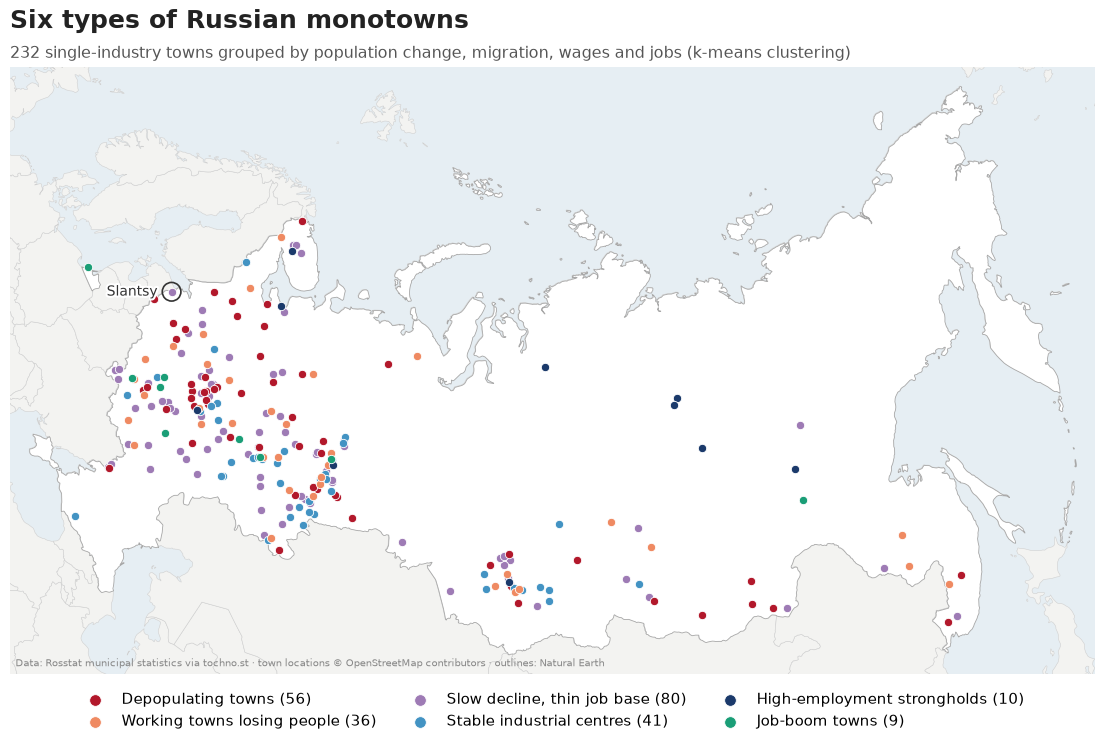

In [18]:
# static map of the six types for the README
import matplotlib.patheffects as pe

world = gpd.read_file("https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip")
PROJ = "+proj=aea +lat_1=52 +lat_2=68 +lat_0=60 +lon_0=95 +datum=WGS84 +units=m"
world_p = world.to_crs(PROJ)

# Russia is split at the 180th meridian; merge the pieces so no line crosses Chukotka
russia_shape = world_p.loc[world_p["ADMIN"] == "Russia", "geometry"].iloc[0].buffer(1000).buffer(-1000)
russia = gpd.GeoDataFrame(geometry=[russia_shape], crs=PROJ)

pts = gpd.GeoDataFrame(towns, geometry=gpd.points_from_xy(towns["lon"], towns["lat"]),
                       crs="EPSG:4326").to_crs(PROJ)

fig, ax = plt.subplots(figsize=(14, 8.5))
ax.set_facecolor("#e6eef3")                                    # sea
world_p.plot(ax=ax, color="#f3f3f1", edgecolor="#d0d0d0", linewidth=0.4)
russia.plot(ax=ax, color="white", edgecolor="#a8a8a8", linewidth=0.6)

# draw the largest types first so the small ones stay visible on top
handles = {}
for t in towns["type"].value_counts().index:
    sub = pts[pts["type"] == t]
    handles[t] = ax.scatter(sub.geometry.x, sub.geometry.y, s=36, color=COLORS[t],
                            edgecolor="white", linewidth=0.6, zorder=3)

# Slantsy: thin ring around its point, label to the left over the Gulf of Finland
x, y = pts.loc[pts["number"] == 109, "geometry"].iloc[0].coords[0]
ax.scatter(x, y, s=180, facecolor="none", edgecolor="#333333", linewidth=1.2, zorder=4)
ax.annotate("Slantsy", (x, y), xytext=(-10, 0), textcoords="offset points",
            ha="right", va="center", fontsize=10, color="#333333", zorder=5,
            path_effects=[pe.withStroke(linewidth=3, foreground="white")])

# frame: the whole of Russia, no axis ticks, labels or border
xmin, ymin, xmax, ymax = russia.total_bounds
ax.set_xlim(xmin - 150_000, xmax + 150_000)
ax.set_ylim(ymin - 150_000, ymax + 150_000)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
for spine in ax.spines.values():
    spine.set_visible(False)

# legend below the map, ordered from most distressed to strongest
ax.legend([handles[t] for t in COLORS],
          [f"{t} ({(towns['type'] == t).sum()})" for t in COLORS],
          loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=3,
          frameon=False, fontsize=10.5, markerscale=1.4, columnspacing=2)

ax.set_title("Six types of Russian monotowns", loc="left", fontsize=18,
             weight="bold", color="#222222", pad=28)
ax.text(0, 1.015, "232 single-industry towns grouped by population change, migration, "
        "wages and jobs (k-means clustering)", transform=ax.transAxes,
        fontsize=11.5, color="#555555")
ax.text(0.005, 0.012, "Data: Rosstat municipal statistics via tochno.st · town locations "
        "© OpenStreetMap contributors · outlines: Natural Earth",
        transform=ax.transAxes, fontsize=7.5, color="#888888")

os.makedirs("../figures", exist_ok=True)
plt.savefig("../figures/monotown_types_map.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()